In [222]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys
from SiEPIC.utils import klive

# Generic Imports
import os
import pya
from pya import *
import numpy as np
import pandas as pd
from SiEPIC.utils import klive
from SiEPIC.scripts import connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC._globals import Python_Env
from SiEPIC.utils.layout import new_layout
import sys
import openpyxl


if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "Shallow_Etch_BTO_PDK","klayout"))

    # Now try importing the PDK
    import Shallow_Etch_BTO



In [223]:
tech_name = 'Shallow_Etch_BTO'  
gclib_name = 'Shallow_Etch_BTO'
lib_name = 'Shallow_Etch_BTO'


chip_name = 'SiEPICfab_bto'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_bto'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan

def GDS_Export(topcell,cellname):
    # Export for fabrication, removing PCells
    path = os.path.join(f"gds_in")
    #r"D:\Github\SiEPIC-Klayout-in-VSCode\floorplan_btomrr\gds_in"

    file_out = export_layout(topcell, path, cellname, relative_path = '', format='gds', screenshot=True)

    # Display the layout in KLayout, using KLayout Package "klive", which needs to be installed in the KLayout Application
    if Python_Env == 'Script':
        klive.show(file_out, technology=tech_name)

    print('\n COMPLETED \n')


In [224]:
cell1_name = 'cell_ring'  # Change this to the name of the top cell from the floorplan

chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{cell1_name}.oas")  # Name of the soon-to-be chip


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpgwajubte\\cell_ring.gds"}
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpgwajubte\\cell_ring.gds"}


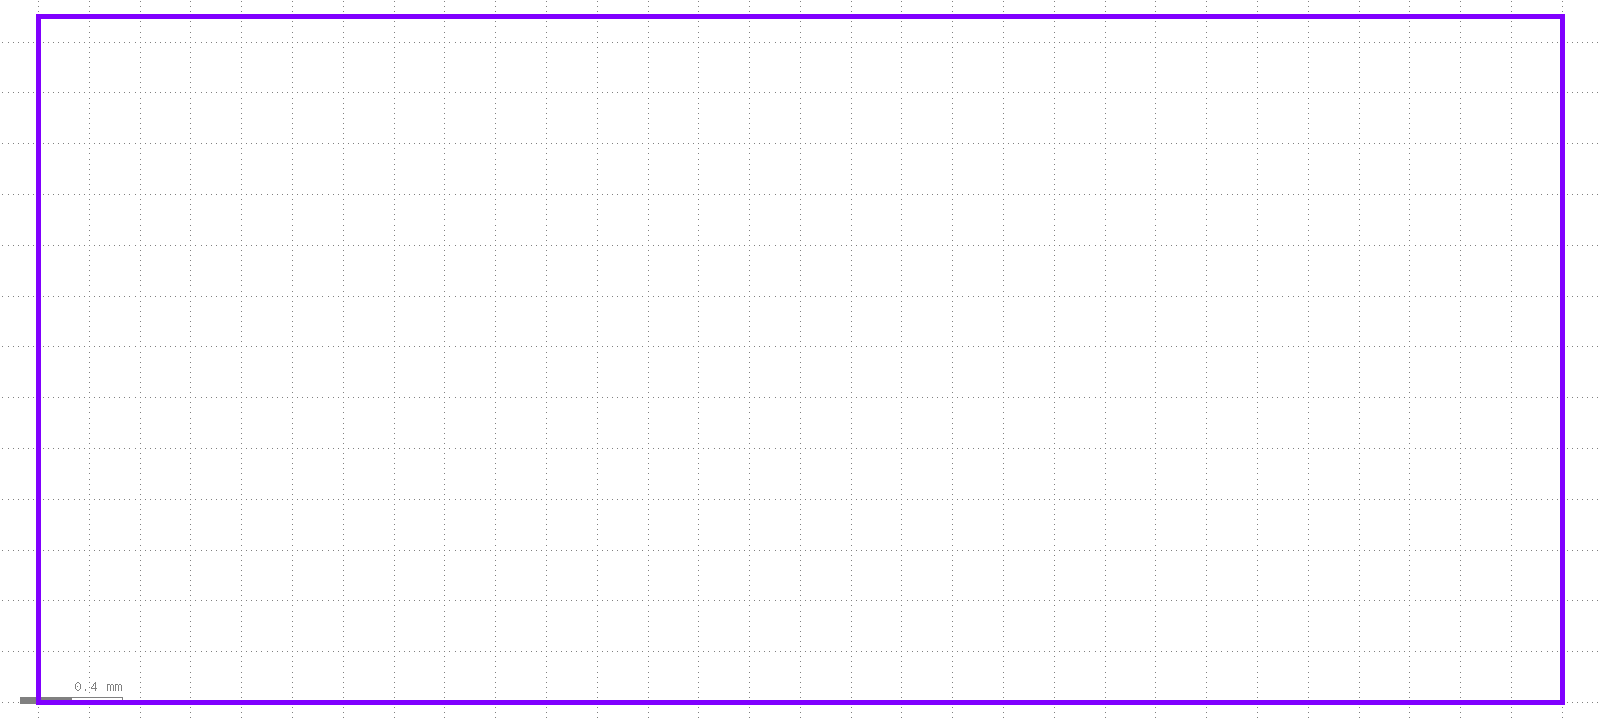

In [225]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(cell1_name)
_top_cell.write(layout_file) #save the layout to a GDS file

"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(cell1_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [226]:
# ============================================================
# GC settings profiles
# Define once and reuse in later cells
# ============================================================
GC_SETTING_FIXED = {
    "gc_cell_name": "BTO_ShEtch_GC_1550",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 1,
}

GC_SETTINGS_UNIVERSAL = {
    "gc_cell_name": "BTO_Universal_GC",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,
    "default_num_gc": 2,
    "label_location": 1,
    "parameters": {
        "target_length": 25,
        "duty_cycle": 0.45,
        "pitch": 1.045,
        "radius": 25,
        "y_span": 15,
        "L_extra": 5,
        "wg_width": 1.0,
    }
}


WG_SETTINGS = {
    "wg_type": "Low-loss Bend Waveguide, w=1.0um r=50um",
}
device_prefix = "opt_in_TE_1550_device_XX"

# margin_x = 250

In [227]:
def place_gc_loopback(
    ParentCell=None,
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs=[(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=[75, 90, 127, -90, 75],
    gc_setting=None,
    tech_name_input=None,
    layout=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Expected gc_setting input:
    - GC_SETTING_FIXED
    - GC_SETTINGS_UNIVERSAL
    or a copied/modified dict (e.g., pitch sweep based on GC_SETTINGS_UNIVERSAL).
    """

    parent_cell = top_cell if ParentCell is None else ParentCell
    if parent_cell is None:
        raise ValueError("ParentCell is required when top_cell is not available")

    ly_local = layout if layout is not None else parent_cell.layout()
    if ly_local is None:
        raise ValueError("Could not resolve layout. Pass layout=ly explicitly.")

    if gc_setting is None:
        gc_setting = GC_SETTING_FIXED

    if not isinstance(gc_setting, dict):
        raise TypeError("gc_setting must be a dict (e.g., GC_SETTING_FIXED or GC_SETTINGS_UNIVERSAL)")

    # Copy to protect global dictionaries when sweeping parameters.
    active_gc_settings = dict(gc_setting)
    active_gc_settings["parameters"] = dict(active_gc_settings.get("parameters", {}))

    # Use global WG_SETTINGS as requested.
    wg_type = WG_SETTINGS.get("wg_type", "")

    # tech_name from input first; fallback to gc settings then global.
    tech_local = tech_name_input if tech_name_input is not None else globals().get("tech_name", None)
    tech_local = active_gc_settings.get("tech_name", tech_local)

    gc_cell_name = active_gc_settings["gc_cell_name"]
    gc_library = active_gc_settings["gc_library"]
    gc_pitch = active_gc_settings["gc_pitch"]
    label_location = active_gc_settings["label_location"]
    gc_parameters = active_gc_settings.get("parameters", {})

    if num_gc is None:
        num_gc = active_gc_settings["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = parent_cell.bbox().height() * dbu

    if xmax is None:
        xmax = parent_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    # Normalize turtle paths.
    # None or [] means auto-routing (no explicit turtle path).
    if turtle_A is None or turtle_A == []:
        turtle_list = [None for _ in port_pairs]
    elif len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    cell = ly_local.create_cell(cellname)

    use_universal_gc = gc_cell_name == "BTO_Universal_GC"

    # Universal/self-defined path: create parameterized PCell from tech.
    # Fixed path: use library loader and fall back to create_cell2 for robustness.
    if use_universal_gc:
        if tech_local is None:
            raise ValueError("tech_name_input is required for UNIVERSAL GC creation")
        gc_probe = ly_local.create_cell("BTO_Universal_GC", tech_local, gc_parameters)
    else:
        gc_probe = None
        if gc_parameters:
            gc_probe = ly_local.create_cell(gc_cell_name, gc_library, gc_parameters)
        if gc_probe is None:
            gc_probe = create_cell2(ly_local, gc_cell_name, gc_library)

    if gc_probe is None:
        raise ValueError(
            f"Could not create/load GC cell '{gc_cell_name}' from library/tech '{gc_library}' with parameters {gc_parameters}"
        )

    top_boundary = parent_cell.bbox().height() * dbu
    near_left = x_pos_GC < 100
    near_right = x_pos_GC > xmax - 150
    near_top = y_pos_GC > top_boundary - 100
    near_bottom = y_pos_GC == 0

    if y_pos_GC == top_boundary or near_top:
        y_pos_GC -= (num_gc - 1) * gc_pitch + gc_probe.bbox().height() * dbu / 2
        if x_pos_GC == 0 or near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu
    elif near_bottom:
        y_pos_GC += gc_probe.bbox().height() * dbu / 2
        if near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu

    # Keep GC anchor fixed inside each device cell; move each device cell in top cell instead.
    # Set local Y so bottom GC opt1 pin is exactly at y=0 in device-cell coordinates.
    local_gc_x = gc_probe.bbox().width() * dbu
    try:
        gc_pin_probe_y = gc_probe.find_pin("opt1").center.to_dtype(dbu).y
    except Exception:
        gc_pin_probe_y = 0.0
    local_gc_y = -gc_pin_probe_y
    cell_origin_x = x_pos_GC 
    cell_origin_y = y_pos_GC
    parent_cell.insert(
        CellInstArray(
            cell.cell_index(),
            Trans(Trans.R0, to_itype(cell_origin_x, dbu), to_itype(cell_origin_y, dbu)),
        )
    )

    # if use_universal_gc:
    #     inst_GCs = coupler_array(
    #         cell,
    #         cell_name=gc_cell_name,  # "BTO_Universal_GC",
    #         cell_library=gc_library,
    #         cell_params=gc_parameters,
    #         x_offset=local_gc_x / dbu,
    #         y_offset=local_gc_y / dbu,
    #         label=device_label,
    #         label_location=label_location,
    #         count=num_gc,
    #     )

    # else:
    #     inst_GCs = coupler_array(
    #         cell,
    #         cell_name=gc_cell_name,
    #         cell_library=gc_library,
    #         x_offset=local_gc_x / dbu,
    #         y_offset=local_gc_y / dbu,
    #         label=device_label,
    #         label_location=label_location,
    #         count=num_gc,
    #     )
    inst_GCs = []
    x_i = to_itype(local_gc_x, dbu)
    for i in range(num_gc):
        y_i = to_itype(local_gc_y + i * gc_pitch, dbu)
        inst = cell.insert(CellInstArray(gc_probe.cell_index(), Trans(Trans.R0, x_i, y_i)))
        inst_GCs.append(inst)
    label_x = to_itype(local_gc_x, dbu)
    label_y = to_itype(0 + label_location * gc_pitch, dbu)
    label = pya.Text(
        f"{device_label}",
        pya.Trans(pya.Trans.R0, label_x, label_y),
    )
    cell.shapes(ly_local.layer(ly_local.TECHNOLOGY['Text'])).insert(label).text_size = 10 / ly_local.dbu

    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i],
            gc_ports[i],
            inst_GCs[j],
            gc_ports[j],
            turtle_A=turtle,
            waveguide_type=wg_type,
            r=wg_bend_radius,
        )

    next_x = cell_origin_x + cell.bbox().width() * dbu + x_spacing #+ gc_probe.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = gc_probe.bbox().width() * dbu
        next_y = cell_origin_y + cell.bbox().bottom * dbu - row_spacing - cell.bbox().height() * dbu

    if next_x > xmax or next_x < 0:
        print(f"WARNING [{cellname}]: next x_pos_GC ({next_x:.1f} um) is out of top_cell x range [0, {xmax:.1f}]")
    if next_y > parent_cell.bbox().height() * dbu or next_y < 0:
        print(f"WARNING [{cellname}]: next y_pos_GC ({next_y:.1f} um) is out of top_cell y range [0, {parent_cell.bbox().height() * dbu:.1f}]")

    return next_x, next_y, xmax




In [228]:
# change function:
def GC_placement(x,y,GC_pcell,ParentCell,angle=0):

    if angle == 0:
        t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y -  GC_pcell.find_pin("opt1").center.to_dtype(dbu).y)
    else:
        t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
    return GC_pcell, GC_inst

def place_VarBEnd(inst4connect,instpin,Bendpin,angle1=-90,angle2=-45):
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,
        })
    inst_VarBend = connect_cell(inst4connect, instpin, VB_pcell , Bendpin)
    return VB_pcell, inst_VarBend

def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):

    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,
        })
    t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
    VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
    return VB_pcell, VB_inst

def SinglePassRacetrackRes(
    x,
    y,
    ParentCell,
    straight_len_um=0,
    gap_um=0.2,
    radius_um=100,
    wg_width_um=1.0,
    waveguide_type=None,
    distance=100,
    gc_pitch_num=1,
    x_spacing=20.0,
    row_spacing=None,
    xmax=None,
    GC_SETTINGS=None,
    devcell_name=None,
    label=None,
    x_margin=250e3,
):
    from SiEPIC.utils.layout import make_pin

    dbu = ly.dbu
    if waveguide_type is None:
        waveguide_type = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.0um r=50um"

    gap_tag = str(gap_um).replace(".", "p")
    base_tag = f"R{int(radius_um)}_G{gap_tag}_L{int(straight_len_um)}"

    if devcell_name is None:
        devcell_name = f"SP_RT_GC_{base_tag}"
    if label is None:
        label = f"opt_in_TE_1550_device_{base_tag}"

    # 1) Half-ring cells (fixed 90 deg orientation)
    rt_core = ly.create_cell(f"SP_RacetrackCore_{base_tag}")
    rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}")

    straight = to_itype(straight_len_um, dbu)

    top_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": True},
    )
    top_inst = rt_core.insert(pya.CellInstArray(top_half.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))

    bot_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": 0, "Lc": 0, "AddDrop": False},
    )
    t_bot = pya.Trans(
        pya.Trans.R180,
        0,
        top_inst.bbox().top + straight + bot_half.bbox().height() - to_itype(wg_width_um, dbu),
    )
    bot_inst = rt_core.insert(pya.CellInstArray(bot_half.cell_index(), t_bot))

    connect_pins_with_waveguide(top_inst,'pin2',bot_inst,'pin4',waveguide_type=wg)
    connect_pins_with_waveguide(top_inst,'pin4',bot_inst,'pin2',waveguide_type=wg)

    rot = pya.DCplxTrans(1.0, -90, False, 0, 0)
    gc_pitch_um = gc_pitch_num * 127.0

    # 2) No VarBend: expose ring top-half drop ports directly
    pinup_local = top_inst.find_pin("pin1").center.to_dtype(dbu)
    pindw_local = top_inst.find_pin("pin3").center.to_dtype(dbu)

    pin_sep_um = abs((rot * pinup_local).y - (rot * pindw_local).y)

    # 3) Rotate core 90 deg clockwise into wrapper and expose routing pins
    rt_wrapper.insert(pya.CellInstArray(rt_core.cell_index(), rot))

    pin1_pt = rot * pinup_local
    pin3_pt = rot * pindw_local

    make_pin(rt_wrapper, "pin_in",  pin1_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 90)
    make_pin(rt_wrapper, "pin_out", pin3_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 270)

    # 4) Container cell: ring wrapper + GCs
    rt_with_gc = ly.create_cell(devcell_name)

    # GC probe cell
    if GC_SETTINGS["gc_cell_name"] == "BTO_Universal_GC":
        gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"], GC_SETTINGS.get("parameters", {}))
    else:
        gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])

    if xmax is None:
        xmax = ParentCell.bbox().width()

    top_boundary = ParentCell.bbox().height()
    near_top = y > top_boundary - to_itype(100, dbu)
    near_bottom = y < to_itype(100, dbu)

    # Match place_gc_loopback behavior: nudge the requested anchor away from top/bottom edges first.
    if x == 0:
        x = x_margin#gc_probe.bbox().width()
    if y == top_boundary or near_top:
        y -= to_itype(gc_pitch_um, dbu) + gc_probe.bbox().height() // 2
    elif y == 0 or near_bottom:
        y += gc_probe.bbox().height() // 2

    # GC y targets in container-local coordinates: bottom GC opt1 at 0, top GC one pitch above.
    gc_pitch = to_itype(gc_pitch_um, dbu)
    gc2_y = 0
    gc1_y = gc2_y + gc_pitch
    gc_mid_y = (gc1_y + gc2_y) // 2

    # Place ring so its (pin_in, pin_out) midpoint is at the GC midpoint.
    ring_pin_in_y = to_itype(rt_wrapper.find_pin("pin_in").center.to_dtype(dbu).y, dbu)
    ring_pin_out_y = to_itype(rt_wrapper.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
    ring_mid_y = (ring_pin_in_y + ring_pin_out_y) // 2
    y_shift = gc_mid_y - ring_mid_y
    x_shift = to_itype(distance, dbu)

    rt_wrapper_inst = rt_with_gc.insert(
        pya.CellInstArray(rt_wrapper.cell_index(), pya.Trans(pya.Trans.R0, x_shift, y_shift))
    )

    # GC x: distance um left of ring pin_in
    pin_in_x = to_itype(rt_wrapper_inst.find_pin("pin_in").center.to_dtype(dbu).x, dbu)
    gc_x = pin_in_x - to_itype(distance, dbu) - gc_probe.bbox().width()

    _, gc1_inst = GC_placement(gc_x, gc1_y, GC_pcell=gc_probe, ParentCell=rt_with_gc, angle=0)
    _, gc2_inst = GC_placement(gc_x, gc2_y, GC_pcell=gc_probe, ParentCell=rt_with_gc, angle=0)

    label_location = GC_SETTINGS.get("label_location", 1)
    label_x = gc_probe.bbox().width()
    label_y = to_itype(label_location * 0, dbu)
    text = pya.Text(f"{label}", pya.Trans(pya.Trans.R0, 0, label_y))
    rt_with_gc.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(text).text_size = 10 / ly.dbu

    connect_pins_with_waveguide(rt_wrapper_inst, "pin_in", gc1_inst, "opt1", waveguide_type=waveguide_type, turtle_A=[distance,90])
    connect_pins_with_waveguide(rt_wrapper_inst, "pin_out", gc2_inst, "opt1", waveguide_type=waveguide_type, turtle_A=[distance,-90])

    # Place container: bottom GC opt1 anchored at (gc_bbox.width, y)
    gc2_pin_x = to_itype(gc2_inst.find_pin("opt1").center.to_dtype(dbu).x, dbu)
    gc2_pin_y = to_itype(gc2_inst.find_pin("opt1").center.to_dtype(dbu).y, dbu)
    place_x = x + (gc_probe.bbox().width() - gc2_pin_x)
    place_y = y - gc2_pin_y
    rt_inst = ParentCell.insert(pya.CellInstArray(rt_with_gc.cell_index(), pya.Trans(pya.Trans.R0, place_x, place_y)))

    if row_spacing is None:
        row_spacing = rt_with_gc.bbox().height() + gc_pitch
    else:
        row_spacing = to_itype(row_spacing, dbu)+rt_with_gc.bbox().height()

    next_x = x + rt_with_gc.bbox().width() + to_itype(x_spacing, dbu)
    next_y = y

    if next_x + rt_with_gc.bbox().width()+x_margin > xmax:
        next_x =0# gc_probe.bbox().width()
        next_y = y - row_spacing

    if next_x > xmax: #or next_x < 0:
        print(f"WARNING [{base_tag}]: next x ({next_x * dbu:.1f} um) is out of top_cell x range [0, {xmax * dbu:.1f}]")
    if next_y > ParentCell.bbox().height() or next_y < 0:
        print(f"WARNING [{base_tag}]: next y ({next_y * dbu:.1f} um) is out of top_cell y range [0, {ParentCell.bbox().height() * dbu:.1f}]")

    return rt_with_gc, rt_inst, gc1_inst, gc2_inst, next_x, next_y, xmax


# ===== Example =====
if 0:
    cellname = "SP_RacetrackMod_Block"
    topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

    FP = pya.Box(0, 0, 6000e3, 2700e3)
    topcell.shapes(ly.layer(ly.TECHNOLOGY["FloorPlan"])).insert(FP)

    wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.0um r=50um"

    radius_um = 80
    straight_len_um = 0
    gap_list = np.linspace(0.2, 0.35, 150)
    params = [(radius_um, gap_value, straight_len_um) for gap_value in gap_list]

    x0 = 00e3
    y0 = 2700e3
    x_spacing = 10.0
    xmax = topcell.bbox().width()

    x = x0
    y = y0
    for i, (rad_um, gap_um, Lc_um) in enumerate(params):
        current_x = x
        current_y = y
        _, rt_inst, _, _, x, y, xmax = SinglePassRacetrackRes(
            x=current_x,
            y=current_y,
            ParentCell=topcell,
            straight_len_um=Lc_um,
            gap_um=gap_um,
            radius_um=rad_um,
            waveguide_type=wg,
            GC_SETTINGS=GC_SETTINGS_UNIVERSAL,
            gc_pitch_num=3,
            x_spacing=-100,
            row_spacing = 25,
            xmax=xmax,
        )
        label = pya.Text(
            f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}",
            pya.Trans(pya.Trans.R0, current_x - 230e3, current_y + rt_inst.bbox().height() // 2 + 120e3),
        )
        topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)

    topcell.show()
    topcell.plot()


Running SWEEP 1: pitch × duty_cycle
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpgwajubte\\cell_ring.gds"}


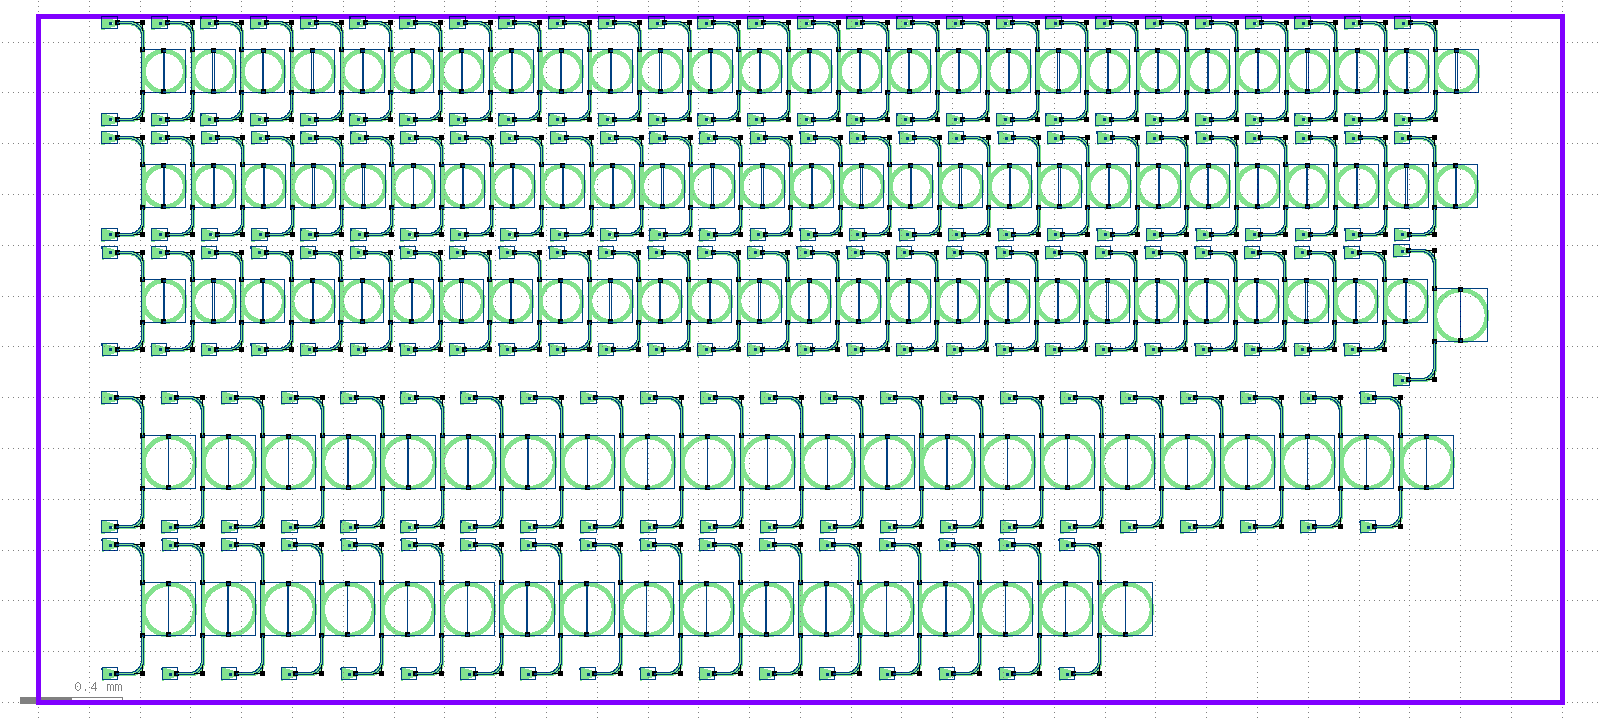

In [229]:
# ============================================================
# Four GC Parameter Sweeps with unique device names
# ============================================================

device_prefix_1550 = "opt_in_TE_1550_device"

device_label_area = "_Ringsweep"

# Reset sweep positions
x_sweep = 0
y_sweep = top_cell.bbox().height() * dbu
x_max = top_cell.bbox().width() 
x_margin = 250e3

# Turtle routing for loopback
loopback_turtle = [75, 90, 127, -90, 75]

# Global index counter for unique device names
global_idx = 0

# Define base settings for sweeps
GC_SETTINGS_UNIVERSAL = {
    "gc_cell_name": "BTO_Universal_GC",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,
    "default_num_gc": 2,
    "label_location": 1,
    "parameters": {
        "target_length": 25,
        "duty_cycle": 0.45,
        "pitch": 1.045,
        "radius": 25,
        "y_span": 15,
        "L_extra": 5,
        "wg_width": 1.0,
    }
}

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.0um r=50um"


gc_sweep = np.array([1.025,1.045])
sweep1_gap = np.round(np.arange(0.075, 1.050 + 1e-9, 0.025), 3)

sweep2_gap = np.round(np.arange(0.05, 1.0 + 1e-9, 0.05), 3)

global_idx = 0
# ---- SWEEP 1: Pitch × Duty Cycle (fixed target_length, radius, y_span, L_extra) ----
print("Running SWEEP 1: pitch × duty_cycle")

x = to_itype(x_sweep, dbu)
y = to_itype(y_sweep, dbu)
rad_um = 80
for i_gc, gc_pitch in enumerate(gc_sweep):
    gc_settings = dict(GC_SETTINGS_UNIVERSAL)
    gc_settings["parameters"] = dict(GC_SETTINGS_UNIVERSAL["parameters"])
    gc_settings["parameters"]["pitch"] = float(gc_pitch)

    for i_gap, gap_um in enumerate(sweep1_gap):    
        devcell_name = f"GC{i_gc}_num{global_idx}_R{rad_um}_G{gap_um*1000:.0f}nm".replace(".","p")
        label = f"{device_prefix_1550}{device_label_area}_{devcell_name}"
       
        current_x = x
        current_y = y
        _, rt_inst, _, _, x, y, xmax = SinglePassRacetrackRes(
            x=current_x,
            y=current_y,
            ParentCell=top_cell,
            straight_len_um=0,
            gap_um=gap_um,
            radius_um=rad_um,
            waveguide_type=wg,
            GC_SETTINGS=gc_settings,
            gc_pitch_num=3,
            x_spacing=-135,
            row_spacing = 25,
            xmax=x_max,
            label = label,
            devcell_name =devcell_name,
            x_margin=x_margin,
        )

        global_idx += 1

y = y-120e3
rad_um = 100    
for i_gc, gc_pitch in enumerate(gc_sweep):
    gc_settings = dict(GC_SETTINGS_UNIVERSAL)
    gc_settings["parameters"] = dict(GC_SETTINGS_UNIVERSAL["parameters"])
    gc_settings["parameters"]["pitch"] = float(gc_pitch)

    for i_gap, gap_um in enumerate(sweep2_gap):    
        devcell_name = f"GC{i_gc}_num{global_idx}_R{rad_um}_G{gap_um*1000:.0f}nm".replace(".","p")
        label = f"{device_prefix_1550}{device_label_area}_{devcell_name}"

        current_x = x
        current_y = y
        _, rt_inst, _, _, x, y, xmax = SinglePassRacetrackRes(
            x=current_x,
            y=current_y,
            ParentCell=top_cell,
            straight_len_um=0,
            gap_um=gap_um,
            radius_um=rad_um,
            waveguide_type=wg,
            GC_SETTINGS=gc_settings,
            gc_pitch_num=4,
            x_spacing=-135,
            row_spacing = 25,
            xmax=x_max,
            label = label,
            devcell_name =devcell_name,
            x_margin=x_margin,
        )
        global_idx += 1

top_cell.show()
top_cell.plot()


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpgwajubte\\cell_ring.gds"}




In [230]:
def SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname_suffix="LT",
    device_label_area="_Default",
    xmax=None,
    num_loopback=2,
    port_pairs_list=None,
    x_spacing=20.0,
    row_spacing=None,
):
    """
    Generate multiple loopback structures with a given prefix.

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        Starting position in microns.

    cellname_prefix : str
        Prefix for cell names (e.g., "GC_loopback").

    device_label_area : str
        Label area suffix (e.g., "_Ladd").

    xmax : float
        Maximum x position before wrapping to next row.

    num_loopback : int
        Number of loopback structures to generate.

    port_pairs_list : list of list of tuple or None
        List of port_pairs for each loopback.
        If None, defaults to [(0, 1), (2, 3)] for all.

    x_spacing, row_spacing : float
        Spacing parameters passed to gc_loopback.

    Returns
    -------
    next_x, next_y, xmax
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, top_cell, dbu, wg_bend_radius

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if port_pairs_list is None:
        port_pairs_list = [[(0, 1), (2, 3)] for _ in range(num_loopback)]

    # Ensure port_pairs_list has the right length
    if len(port_pairs_list) < num_loopback:
        port_pairs_list.extend([[(0, 1), (2, 3)] for _ in range(num_loopback - len(port_pairs_list))])

    # Generate each loopback structure
    for i in range(num_loopback):
        # Create numbered cell name
        cellname = f"GCloopback{cellname_suffix}{i+1}"

        x_pos_GC, y_pos_GC, xmax = place_gc_loopback(
            x_pos_GC=x_pos_GC,
            y_pos_GC=y_pos_GC,
            cellname=cellname,
            device_label=device_prefix + device_label_area + "_" + cellname,
            xmax=None,
            num_gc=None,
            port_pairs=port_pairs_list[i],
            x_spacing=x_spacing,
            row_spacing=row_spacing,
            turtle_A=None,
        )

    return x_pos_GC, y_pos_GC, xmax

# Generate loopback alignment structures
x, y, xmax = SelfDefineAlignment(
    x_pos_GC=x_sweep,
    y_pos_GC=y_sweep,
    cellname_suffix="LT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)  


# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-x_margin,
    y_pos_GC=y_sweep,
    cellname_suffix="RT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)
# top_cell.show()
# top_cell.plot()


# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=current_y,
    cellname_suffix="LB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)

_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-x_margin,
    y_pos_GC=current_y,
    cellname_suffix="RB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)


top_cell.show()
top_cell.plot()



In [231]:
y_sweep

2700.0